# 03 - Baseline Model: Decision Tree


## 1. Data Preparation

In [35]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, log_loss)

In [36]:
!wget https://raw.githubusercontent.com/azzaauliyaul/Detection-of-Stunting-in-Indonesian-Toddlers/main/data/preprocessed_stunting_data.joblib

--2026-11-25 02:16:27--  https://raw.githubusercontent.com/azzaauliyaul/Detection-of-Stunting-in-Indonesian-Toddlers/main/data/preprocessed_stunting_data.joblib
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1580322 (1.5M) [application/octet-stream]
Saving to: ‘preprocessed_stunting_data.joblib.3’

preprocessed_stunti 100%[===================>]   1.51M  --.-KB/s    in 0.02s   

2026-11-25 02:16:27 (68.5 MB/s) - ‘preprocessed_stunting_data.joblib.3’ saved [1580322/1580322]



In [37]:
data = joblib.load("preprocessed_stunting_data.joblib")

X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val     = data["X_val"], data["y_val"]
X_test, y_test   = data["X_test"], data["y_test"]
target_encoder   = data["target_encoder"]
class_weights    = data["class_weights"]
RANDOM_STATE     = data["random_state"]

print(f"Loaded! Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")
print("Target Mapping:", dict(enumerate(target_encoder.classes_)))
print("Class Weights :", class_weights)

target_names = list(target_encoder.classes_)

Loaded! Train: 27,597 | Val: 5,914 | Test: 5,914
Target Mapping: {0: 'normal', 1: 'severely stunted', 2: 'stunted', 3: 'tinggi'}
Class Weights : {0: 0.45814795139119463, 1: 1.5116673970201577, 2: 2.23132276843467, 3: 1.4132015567390415}


## 2. Training Baseline

In [38]:
baseline_dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=None,
    class_weight=class_weights,
    random_state=RANDOM_STATE
)
t0 = time.perf_counter()
baseline_dt.fit(X_train, y_train)
train_time = time.perf_counter() - t0

print(f"Waktu pelatihan : {train_time:.4f} detik")
print("Fitur           :", list(X_train.columns))
print("Kedalaman pohon :", baseline_dt.get_depth())
print("Jumlah daun     :", baseline_dt.get_n_leaves())

Waktu pelatihan : 0.0515 detik
Fitur           : ['Umur (bulan)', 'Jenis Kelamin', 'Tinggi Badan (cm)']
Kedalaman pohon : 21
Jumlah daun     : 1069


## 3. Evaluasi

In [39]:
def evaluate(model, X_, y_, name):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)
    return {
        'Split': name,
        'Accuracy': accuracy_score(y_, pred),
        'Precision (macro)': precision_score(y_, pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_, pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_, pred, average='macro'),
        'F1 (weighted)': f1_score(y_, pred, average='weighted'),
        'Log loss': log_loss(y_, proba, labels=list(range(len(target_names)))),
    }

results = pd.DataFrame([
    evaluate(baseline_dt, X_train, y_train, 'Train'),
    evaluate(baseline_dt, X_val, y_val, 'Validation'),
    evaluate(baseline_dt, X_test, y_test, 'Test'),
]).set_index('Split').round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Log loss
Split,,,,,,
Train,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Validation,0.9868,0.9820,0.9806,0.9813,0.9868,0.4754
Test,0.9855,0.9794,0.9784,0.9789,0.9855,0.5241


In [40]:
print("=== Classification Report (Validation) ===")
print(classification_report(y_val, baseline_dt.predict(X_val), target_names=target_names, digits=4))
print("=== Classification Report (Test) ===")
y_pred_test = baseline_dt.predict(X_test)
print(classification_report(y_test, y_pred_test, target_names=target_names, digits=4))

=== Classification Report (Validation) ===
                  precision    recall  f1-score   support

          normal     0.9913    0.9938    0.9926      3227
severely stunted     0.9857    0.9836    0.9846       978
         stunted     0.9607    0.9593    0.9600       663
          tinggi     0.9904    0.9857    0.9880      1046

        accuracy                         0.9868      5914
       macro avg     0.9820    0.9806    0.9813      5914
    weighted avg     0.9868    0.9868    0.9868      5914

=== Classification Report (Test) ===
                  precision    recall  f1-score   support

          normal     0.9916    0.9932    0.9924      3228
severely stunted     0.9796    0.9826    0.9811       978
         stunted     0.9561    0.9532    0.9546       662
          tinggi     0.9904    0.9847    0.9875      1046

        accuracy                         0.9855      5914
       macro avg     0.9794    0.9784    0.9789      5914
    weighted avg     0.9855    0.9855    0.98

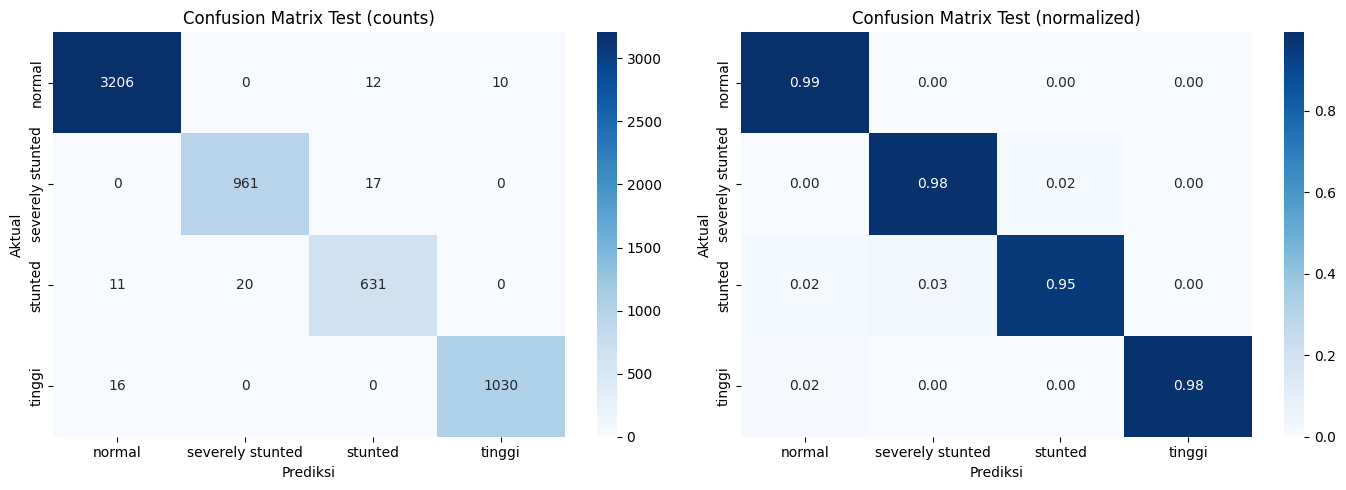

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, norm in zip(axes, [None, 'true']):
    cm = confusion_matrix(y_test, y_pred_test, normalize=norm)
    sns.heatmap(cm, annot=True, fmt='.2f' if norm else 'd', cmap='Blues',
                xticklabels=target_names, yticklabels=target_names, ax=ax)
    ax.set_title('Confusion Matrix Test (' + ('normalized' if norm else 'counts') + ')')
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout(); plt.show()

## 4. Interpretasi Model

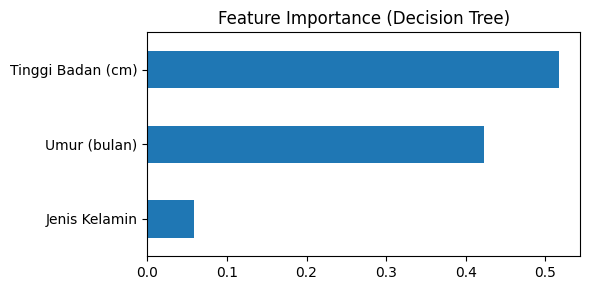

,0
Tinggi Badan (cm),0.5177
Umur (bulan),0.4232
Jenis Kelamin,0.0591


In [42]:
# Pentingnya fitur
imp = pd.Series(baseline_dt.feature_importances_, index=X_train.columns).sort_values()
imp.plot(kind='barh', figsize=(6, 3), title='Feature Importance (Decision Tree)')
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4)

## 5. Analisis Kedalaman Pohon

pengaruh `max_depth` terhadap F1 macro di train dan validation.

,max_depth,F1 macro train,F1 macro val
0,2,0.3156,0.3260
1,4,0.4959,0.4990
2,6,0.6348,0.6390
3,8,0.7794,0.7782
4,10,0.8849,0.8785
5,12,0.9458,0.9325
6,15,0.9874,0.9701
7,20,1.0000,0.9813
8,25,1.0000,0.9813
9,None,1.0000,0.9813


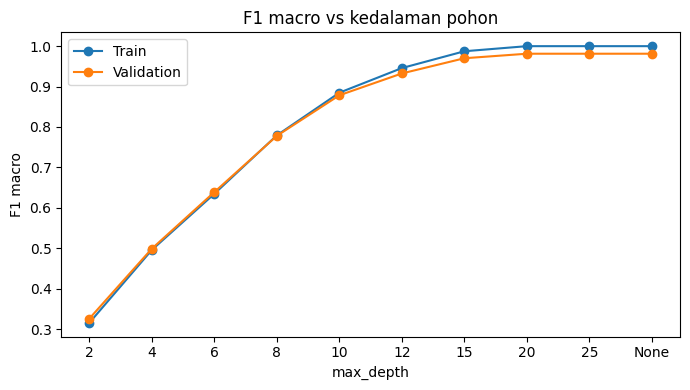

In [43]:
depths = [2, 4, 6, 8, 10, 12, 15, 20, 25, None]
rows = []
for dpt in depths:
    m = DecisionTreeClassifier(max_depth=dpt, class_weight=class_weights, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append({
        'max_depth': 'None' if dpt is None else dpt,
        'F1 macro train': f1_score(y_train, m.predict(X_train), average='macro'),
        'F1 macro val': f1_score(y_val, m.predict(X_val), average='macro'),
    })
depth_df = pd.DataFrame(rows).round(4)
display(depth_df)

plt.figure(figsize=(7, 4))
plt.plot(depth_df['max_depth'].astype(str), depth_df['F1 macro train'], marker='o', label='Train')
plt.plot(depth_df['max_depth'].astype(str), depth_df['F1 macro val'], marker='o', label='Validation')
plt.xlabel('max_depth'); plt.ylabel('F1 macro'); plt.title('F1 macro vs kedalaman pohon'); plt.legend()
plt.tight_layout(); plt.show()

In [44]:
# Simpan model & preprocessing
import joblib
joblib.dump({'model': baseline_dt, 'scaler': scaler,
             'gender_encoder': gender_encoder, 'target_encoder': target_encoder},
            'baseline_decision_tree.joblib')
results.to_csv('baseline_decision_tree_results.csv')